<a href="https://colab.research.google.com/github/shafanh/zomato-data-analysis-using-python/blob/main/Zomato_Data_Analysis_Using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Zomato Data Analysis Using Python**

Understanding customer preferences and restaurant trends is important for making informed business decisions in food industry. In this article, we will analyze Zomato’s restaurant dataset using Python to find meaningful insights. We aim to answer questions such as:


*   Do more restaurants provide online delivery compared to offline services?
*   Which types of restaurants are most favored by the general public?
*   What price range do couples prefer for dining out?

## Install Library

In [ ]:
!pip install pandas numpy matplotlib seaborn

## Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Create Dataframe

In [ ]:
dataframe = pd.read_csv("/content/Zomato-data-.csv")
print (dataframe.head())

                    name online_order book_table   rate  votes  \
0                  Jalsa          Yes        Yes  4.1/5    775   
1         Spice Elephant          Yes         No  4.1/5    787   
2        San Churro Cafe          Yes         No  3.8/5    918   
3  Addhuri Udupi Bhojana           No         No  3.7/5     88   
4          Grand Village           No         No  3.8/5    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


## Data Cleaning and Preparation

1. Convert the rate column to a float by removing denominator characters.

```
dataframe['rate']=dataframe['rate'].apply(handleRate)
```
Applies the handleRate function to clean and convert each rating value in the 'rate' column.





In [ ]:
def handleRate(value):
  value=str(value).split('/')
  value=value[0];
  return float(value)

dataframe['rate']=dataframe['rate'].apply(handleRate)
print(dataframe.head())

                    name online_order book_table  rate  votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   approx_cost(for two people) listed_in(type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


2. Getting summary of the dataframe info

In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


3. Checking for missing value/null

In [ ]:
print(dataframe.isnull().sum())

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64


There is **NO MISSING VALUE** in dataframe

## Exploring Restaurant Types

1. See column to identify popular restaurant categories

Text(0.5, 0, 'Type of Restaurant')

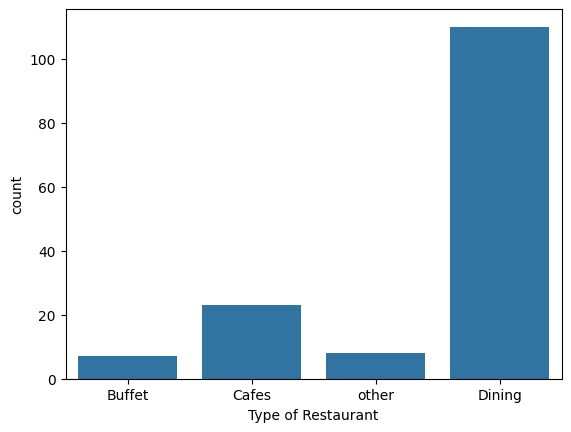

In [ ]:
sns.countplot(x=dataframe['listed_in(type)'])
plt.xlabel("Type of Restaurant")

**Conclusion**: The majority type of restaurant is **Dining** rastaurant

2. Votes by Restaurant Type

Text(0, 0.5, 'Votes')

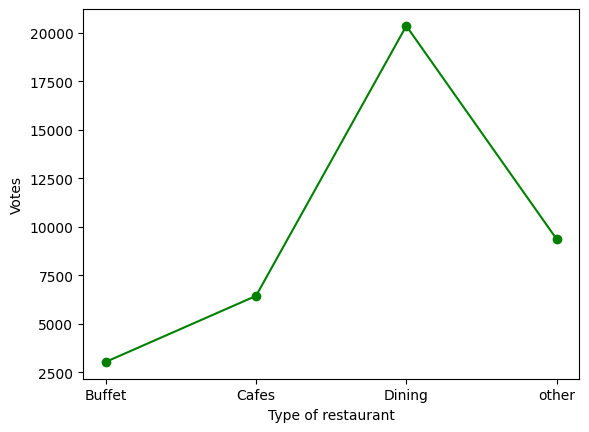

In [ ]:
grouped_data = dataframe.groupby('listed_in(type)')['votes'].sum()
result = pd.DataFrame({'votes': grouped_data})
plt.plot(result, c='green', marker='o')
plt.xlabel('Type of restaurant')
plt.ylabel('Votes')

**Conclusion**: **A large number of individuals** preferred **Dining** restaurant

## Identify the Most Voted Restaurant

In [ ]:
max_votes=dataframe['votes'].max()
restaurant_with_max_votes=dataframe.loc[dataframe['votes']==max_votes,'name']
print('Restaurant(s) with the most votes:')
print(restaurant_with_max_votes)

Restaurant(s) with the most votes:
38    Empire Restaurant
Name: name, dtype: object


## Online Order Availability

Text(0.5, 0, 'Online Order')

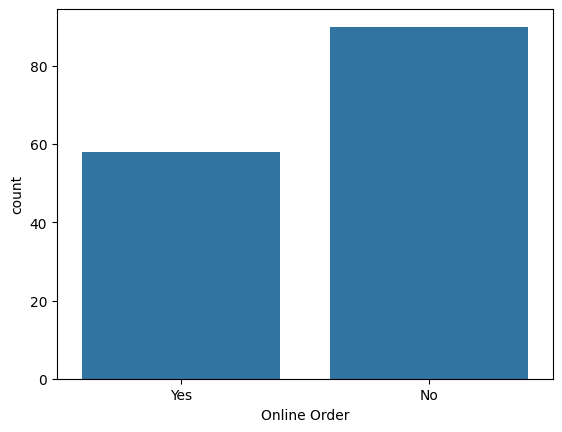

In [ ]:
sns.countplot(x=dataframe['online_order'])
plt.xlabel("Online Order")

**Conclusion**: **Majority** of the restaurants **don't** accept online orders

## Analyze Ratings

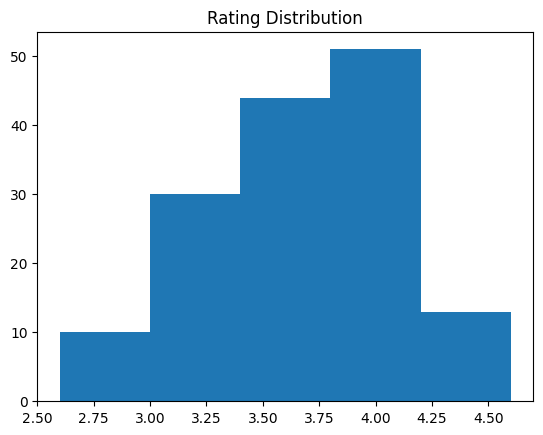

In [ ]:
plt.hist(dataframe['rate'],bins=5)
plt.title('Rating Distribution')
plt.show()

**Conslusion**: **The majority of restaurants** received ratings ranging from **3.5 to 4.0**

## Approximate Cost for Couples

<Axes: xlabel='approx_cost(for two people)', ylabel='count'>

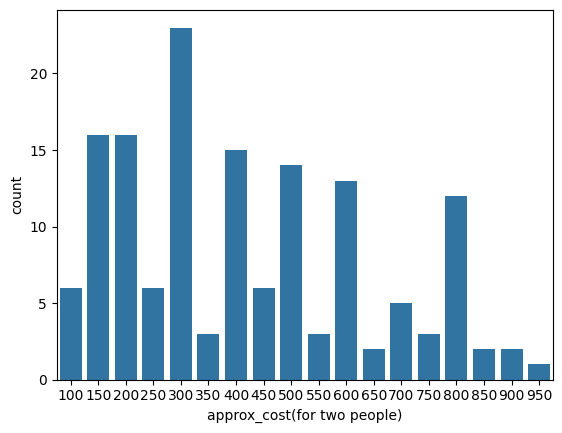

In [ ]:
couple_data=dataframe['approx_cost(for two people)']
sns.countplot(x=couple_data)

**Conclusion**: **The majority of couples** prefer restaurants with an **approximate cost 300 rupees**

## Rating Comparison - Online vs Offline Orders

<Axes: xlabel='online_order', ylabel='rate'>

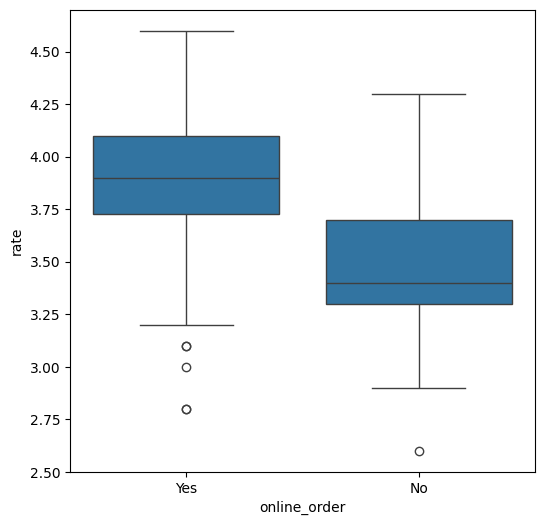

In [ ]:
plt.figure(figsize=(6,6))
sns.boxplot(x='online_order',y='rate',data=dataframe)

Conclusion: Online order received excellent ratings compared to offline order which obtained lower ratings

## Order Mode Preferences by Restaurant Type

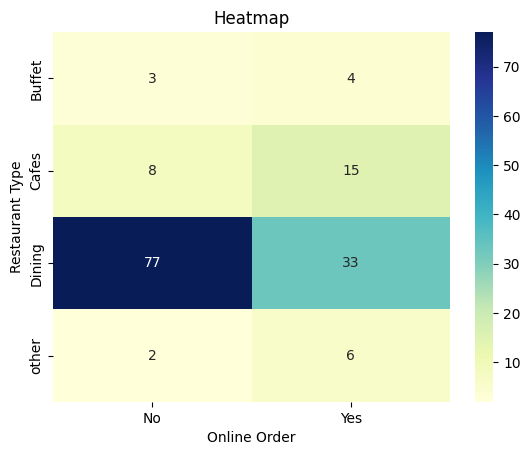

In [ ]:
pivot_table=dataframe.pivot_table(index='listed_in(type)',columns='online_order', aggfunc='size', fill_value=0)
sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt='d')
plt.title('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Restaurant Type')
plt.show()

This suggests that client prefer to place in person orders at the restaurant but prefer ordeing online at cafes.